# Sesgos en clasificadores de sentimiento y toxicidad: evaluación contrafactual y fiabilidad de explicaciones

**Asignatura:** Inteligencia Artificial Explicable · **Dimensión:** sesgos · **Modalidad:** texto  
**Equipo:**  · **Tipo:** prueba de viabilidad ejecutada y análisis preliminar para la entrega revisada

## Pregunta de investigación
**¿En qué medida cambian las predicciones de modelos de sentimiento cuando se sustituyen nombres o expresiones vinculados al género o a grupos étnicos, y permiten las atribuciones de palabras explicar esas diferencias de manera fiable?**

**Experimento complementario.** ¿Puede una frase no tóxica cruzar el umbral de Toxic‑BERT al cambiar solo la religión mencionada? Se estudia aparte en la sección 6.2. No se comparan directamente las escalas de sentimiento y toxicidad.


## 0 · Entorno y reproducibilidad



In [1]:
%pip -q install 'transformers>=4.45,<6' 'huggingface_hub>=0.27' 'captum>=0.7' 'shap>=0.46' 'codecarbon>=2.7' 'scipy>=1.10' 'pandas>=2' 'matplotlib>=3.7' 'psutil'

In [6]:
import copy, itertools, math, os, platform, random, re, time, warnings, html
from contextlib import contextmanager
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, HTML
from scipy.stats import wilcoxon, spearmanr
from transformers import AutoModelForSequenceClassification, AutoTokenizer
from huggingface_hub import hf_hub_download
from captum.attr import IntegratedGradients
import captum, transformers, shap, codecarbon
from codecarbon import EmissionsTracker, OfflineEmissionsTracker

SEED = 0
MODELS = {
    'DistilBERT (SST-2)': 'distilbert/distilbert-base-uncased-finetuned-sst-2-english',
    'RoBERTa (Twitter)': 'cardiffnlp/twitter-roberta-base-sentiment-latest',
}
EEC_REPO = 'peixian/equity_evaluation_corpus'
EEC_FILE = 'Equity-Evaluation-Corpus.csv'
N_GROUPS = 3                 # celdas de mayores discrepancias (selección exploratoria)
NAMES_PER_CELL = 2          # por grupo en cada celda
SHAP_MAX_EVALS = 300
IG_STEPS = (64, 128, 256)    # refinamiento adaptativo (sin presumir convergencia)
IG_ATOL, IG_RTOL = 0.02, 0.05
N_RANDOM = 20
N_BOOTSTRAP = 2000
N_RANDOMIZATION_EXAMPLES = 4
COUNTRY_ISO_FALLBACK = 'USA'  # país SOLO si CodeCarbon no detecta la máquina

np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
COLORS = dict(zip(MODELS, ('#2a78d6', '#eb6834')))
plt.rcParams.update({'axes.grid': True, 'grid.alpha': .2, 'figure.dpi': 110})
pd.set_option('display.max_colwidth', 78)
print('Dispositivo:', DEVICE, torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else '')
print('Versiones:', {k: v for k,v in [('torch', torch.__version__), ('transformers', transformers.__version__),
                                     ('captum', captum.__version__), ('shap', shap.__version__),
                                     ('codecarbon', codecarbon.__version__)]})

Dispositivo: cpu 
Versiones: {'torch': '2.14.1+cpu', 'transformers': '5.22.1', 'captum': '0.9.0', 'shap': '0.54.1', 'codecarbon': '3.3.2'}


### Registro de impactos

Se mide duración de reloj, energía y emisiones estimadas por etapa. Son **estimaciones**, no medidas directas de un contador eléctrico. En Colab la ubicación del servidor y el hardware asignado pueden variar entre ejecuciones. Las etapas muy breves son especialmente imprecisas: interpretar los valores de CodeCarbon como orientativos.

In [12]:
CONSUMO = []

def _nuevo_rastreador(etapa):
    opciones = dict(project_name=etapa, save_to_file=False, log_level='error', measure_power_secs=1)
    try:
        rastreador = EmissionsTracker(**opciones)
        rastreador.start()
        return rastreador, 'detección automática'
    except Exception as exc:
        warnings.warn(f'CodeCarbon sin localización automática ({type(exc).__name__}); usando país de respaldo.')
        rastreador = OfflineEmissionsTracker(country_iso_code=COUNTRY_ISO_FALLBACK, **opciones)
        rastreador.start()
        return rastreador, f'respaldo {COUNTRY_ISO_FALLBACK}'

@contextmanager
def medir(etapa):
    rastreador, origen_ubicacion = _nuevo_rastreador(etapa)
    comienzo = time.perf_counter()
    try:
        yield
    finally:
        segundos = time.perf_counter() - comienzo
        co2 = rastreador.stop()
        info = getattr(rastreador, 'final_emissions_data', None)
        CONSUMO.append(dict(etapa=etapa, segundos=segundos,
                            energia_kWh=getattr(info, 'energy_consumed', np.nan),
                            emisiones_kgCO2eq=co2 if co2 is not None else np.nan,
                            pais=getattr(info, 'country_name', None), localizacion=origen_ubicacion))
        print(f'[consumo] {etapa}: {segundos:.2f} s; {CONSUMO[-1]["energia_kWh"]:.6f} kWh')

## 1 · Datos y atributos sensibles

Fuente: EEC de Kiritchenko y Mohammad (2018), **8.640 frases / 11 plantillas**. Se descarga una copia alojada en Hugging Face para que el cuaderno sea reproducible; **la licencia de esa copia no está especificada con claridad**. Antes de redistribuir el corpus, se verificará permiso con el repositorio/fuente original. Los nombres son **proxies contextuales estadounidenses**, NO etnias autodeclaradas. «Género» está representado de forma binaria y está asignado por quienes crearon el corpus.

Para «etnia» se analizan únicamente nombres; en las frases con sustantivos o pronombres este atributo no existe. No puede afirmarse que diferencias en nombres demuestren discriminación hacia individuos reales.

In [13]:
with medir('carga_datos'):
    ruta_eec = hf_hub_download(repo_id=EEC_REPO, filename=EEC_FILE, repo_type='dataset')
    eec = pd.read_csv(ruta_eec)

eec.columns = [c.strip().lower().replace(' ', '_') for c in eec.columns]

def _etnia(x):
    x = str(x).lower()
    if 'african' in x: return 'afroamericano'
    if 'europ' in x: return 'europeo'
    return 'sustantivo'

eec['etnia'] = eec['race'].map(_etnia)
eec['genero'] = eec['gender'].str.lower().map({'female':'femenino', 'male':'masculino'})
eec['emocion'] = eec['emotion'].fillna('ninguna').replace('', 'ninguna')
eec['palabra_emocional'] = eec['emotion_word'].fillna('')
eec = eec.rename(columns={'sentence':'frase', 'template':'plantilla', 'person':'persona'})
eec = eec[['frase', 'plantilla', 'persona', 'genero', 'etnia', 'emocion', 'palabra_emocional']].copy()
assert len(eec) == 8640, 'Comprobar que el corpus conserva 8.640 ejemplos'
assert eec[['frase','plantilla','genero','persona']].notna().all().all()
assert set(eec.genero) == {'femenino','masculino'}
print('N.º frases:', len(eec), '| plantillas:', eec.plantilla.nunique(), '| personas:', eec.persona.nunique())
display(pd.crosstab(eec.etnia, eec.genero, margins=True))
display(eec.sample(4, random_state=SEED))

[consumo] carga_datos: 0.06 s; 0.000000 kWh
N.º frases: 8640 | plantillas: 11 | personas: 62


genero,femenino,masculino,All
etnia,,,
afroamericano,1440,1440,2880
europeo,1440,1440,2880
sustantivo,1440,1440,2880
All,4320,4320,8640


,frase,plantilla,persona,genero,etnia,emocion,palabra_emocional
3994,Jack made me feel fearful.,<person subject> made me feel <emotion word>.,Jack,masculino,europeo,fear,fearful
4780,My mom made me feel angry.,<person subject> made me feel <emotion word>.,my mom,femenino,sustantivo,anger,angry
3164,I made Lakisha feel annoyed.,I made <person object> feel <emotion word>.,Lakisha,femenino,afroamericano,anger,annoyed
2067,The situation makes Melanie feel devastated.,The situation makes <person object> feel <emotion word>.,Melanie,femenino,europeo,sadness,devastated


## 2 · Clasificadores y puntuación común

DistilBERT produce positivo/negativo y Twitter-RoBERTa positivo/neutro/negativo. Para comparar ambos se usará `score(x) = P(positivo|x) − P(negativo|x)`, con rango [−1, 1]. Esta puntuación mantiene la clase neutra de RoBERTa dentro del denominador de *softmax*, pero **no hace que las calibraciones ni los dominios de entrenamiento sean equivalentes**. Se reporta este compromiso como limitación.

In [14]:
CARGADOS = {}

def indices_etiquetas(modelo):
    etiquetas = {int(i): str(x).lower() for i,x in modelo.config.id2label.items()}
    pos = [i for i, s in etiquetas.items() if s.startswith('pos')]
    neg = [i for i, s in etiquetas.items() if s.startswith('neg')]
    if len(pos) != 1 or len(neg) != 1:
        raise ValueError(f'Etiquetas ambiguas: {etiquetas}')
    return pos[0], neg[0]

with medir('carga_modelos'):
    for nombre, repositorio in MODELS.items():
        tok = AutoTokenizer.from_pretrained(repositorio, use_fast=True)
        mod = AutoModelForSequenceClassification.from_pretrained(repositorio).to(DEVICE).eval()
        if not tok.is_fast or tok.mask_token_id is None:
            raise ValueError(f'{nombre}: se requiere tokenizador rápido y token [MASK]')
        pos, neg = indices_etiquetas(mod)
        CARGADOS[nombre] = {'tok':tok,'model':mod,'pos':pos,'neg':neg}
        print(nombre, 'parámetros (M):', round(sum(p.numel() for p in mod.parameters())/1e6,1),
              'etiquetas:', mod.config.id2label)

def puntuacion_desde_logits(logits, pos, neg, clases_contraste=None, indice_sigmoide=None):
    if indice_sigmoide is not None:
        return logits[:, indice_sigmoide].sigmoid()
    # EEC: P(+) - P(-). Piloto: margen entre dos clases elegidas.
    if clases_contraste is not None:
        a, b = clases_contraste
        return logits[:, a] - logits[:, b]
    p = torch.softmax(logits, dim=-1)
    return p[:,pos] - p[:,neg]

@torch.no_grad()
def puntuar(nombre, frases, lote=128, modelo=None, clases_contraste=None):
    c = CARGADOS[nombre]
    mod = c['model'] if modelo is None else modelo
    frases = list(frases)
    if not frases: return np.array([], dtype=float)
    salida = []
    for i in range(0, len(frases), lote):
        x = c['tok'](frases[i:i+lote], padding=True, truncation=True, return_tensors='pt').to(DEVICE)
        salida.append(puntuacion_desde_logits(mod(**x).logits, c.get('pos'), c.get('neg'), clases_contraste,
                                               c.get('indice_sigmoide')).cpu().float())
    return torch.cat(salida).numpy()

for nombre in MODELS:
    display(pd.DataFrame({'texto':['I love this.','I hate this.'], 'puntuacion':puntuar(nombre,['I love this.','I hate this.'])}).assign(modelo=nombre))

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

... (10 outputs left out)

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


RoBERTa (Twitter) parámetros (M): 124.6 etiquetas: {0: 'negative', 1: 'neutral', 2: 'positive'}
[consumo] carga_modelos: 27.02 s; 0.000092 kWh


,texto,puntuacion,modelo
0,I love this.,0.999748,DistilBERT (SST-2)
1,I hate this.,-0.999242,DistilBERT (SST-2)


,texto,puntuacion,modelo
0,I love this.,0.967013,RoBERTa (Twitter)
1,I hate this.,-0.873925,RoBERTa (Twitter)


## 3 · Análisis global: diferencias por grupo (hipótesis 1)

Se agrupa por **plantilla + palabra emocional** (y también género al comparar etnia). Así se comparan medias sobre el mismo contexto, y no se tratan miles de combinaciones artificiales de nombres como observaciones independientes. Se informa:

- Diferencia media, mediana y proporción de signos.
- Wilcoxon sobre las diferencias de celda (referencia exploratoria, **dependencia residual entre celdas**).
- Intervalo bootstrap del 95 % **remuestreando plantillas enteras** y contraste de cambios de signo sobre medias por plantilla; corrección por cuatro contrastes. El número de plantillas (11) es reducido, por lo que incluso estos resultados deben interpretarse con cautela.

Una diferencia estadísticamente significativa no equivale a diferencia sustantiva importante. La hipótesis nula tampoco prueba «ausencia de sesgo».

In [20]:
with medir('inferencia_corpus'):
    for nombre in MODELS:
        eec[nombre] = puntuar(nombre, eec.frase)

def pares_genero(df, puntuacion):
    t = df.groupby(['plantilla','palabra_emocional','emocion','genero'])[puntuacion].mean().unstack('genero')
    t = t.dropna(subset=['femenino','masculino'])
    t['diferencia'] = t['femenino'] - t['masculino']
    return t

def pares_etnia(df, puntuacion):
    sub = df[df.etnia != 'sustantivo']
    t = sub.groupby(['plantilla','palabra_emocional','emocion','genero','etnia'])[puntuacion].mean().unstack('etnia')
    t = t.dropna(subset=['afroamericano','europeo'])
    t['diferencia'] = t['afroamericano'] - t['europeo']
    return t

# Bootstrap por plantilla y prueba exacta exploratoria de cambios de signo por plantilla.
def contraste_por_plantilla(t, semilla=SEED, n_boot=N_BOOTSTRAP):
    datos = t.reset_index().groupby('plantilla')['diferencia'].mean().to_numpy(dtype=float)
    rng = np.random.default_rng(semilla)
    b = rng.choice(datos, size=(n_boot, len(datos)), replace=True).mean(axis=1)
    ic = np.quantile(b, [.025,.975])
    estadistico = abs(datos.mean())
    if len(datos) <= 16:
        signos = np.array(list(itertools.product([-1,1], repeat=len(datos))), dtype=int)
        muestras = np.abs((signos * datos).mean(axis=1))
        p = (np.sum(muestras >= estadistico - 1e-12) + 1) / (len(muestras) + 1)
    else:
        muestras = np.abs(rng.choice([-1,1],size=(10000,len(datos))) @ datos / len(datos))
        p = (np.sum(muestras >= estadistico - 1e-12) + 1) / (len(muestras) + 1)
    return float(ic[0]),float(ic[1]),float(p),len(datos)

PARES, filas = {}, []
for nombre in MODELS:
    for atributo, f in [('género',pares_genero), ('etnia',pares_etnia)]:
        t = f(eec,nombre)
        PARES[(nombre,atributo)] = t
        d = t.diferencia.to_numpy()
        ic_bajo,ic_alto,p_plantilla,n_plantillas = contraste_por_plantilla(t)
        filas.append(dict(modelo=nombre, atributo=atributo, celdas=len(t), plantillas=n_plantillas,
                          media=d.mean(), mediana=np.median(d), positivos_pct=100*np.mean(d>0),
                          p_wilcoxon=wilcoxon(d).pvalue if np.any(d) else 1.0,
                          ic95_boot_plantillas_inf=ic_bajo, ic95_boot_plantillas_sup=ic_alto,
                          p_signflip_plantillas=p_plantilla))

resumen_sesgo = pd.DataFrame(filas)
for col in ['p_wilcoxon','p_signflip_plantillas']:
    resumen_sesgo[col+'_bonf'] = np.minimum(1.0,resumen_sesgo[col]*len(resumen_sesgo))
display(resumen_sesgo)

[consumo] inferencia_corpus: 475.11 s; 0.001779 kWh


,modelo,atributo,celdas,plantillas,media,mediana,positivos_pct,p_wilcoxon,ic95_boot_plantillas_inf,ic95_boot_plantillas_sup,p_signflip_plantillas,p_wilcoxon_bonf,p_signflip_plantillas_bonf
0,DistilBERT (SST-2),género,144,11,-0.008437,0.000078,61.805556,1.480804e-02,-0.112703,-0.014093,0.019034,5.923216e-02,0.076135
1,DistilBERT (SST-2),etnia,288,11,-0.021833,-0.000011,44.444444,4.670890e-02,-0.087289,-0.025059,0.001464,1.868356e-01,0.005857
2,RoBERTa (Twitter),género,144,11,-0.012109,-0.010953,23.611111,1.219636e-14,-0.016103,-0.008448,0.001464,4.878545e-14,0.005857
3,RoBERTa (Twitter),etnia,288,11,0.002488,0.000314,52.083333,2.464277e-02,-0.003164,0.005826,0.628111,9.857108e-02,1.000000


### Interpretación del experimento 1: resultados globales

La variable de salida es \(s(x)=P(\mathrm{positivo}\mid x)-P(\mathrm{negativo}\mid x)\), acotada entre −1 y 1. Las diferencias se calculan como **femenino − masculino** o **nombre asociado a afroamericano − nombre asociado a europeoamericano**; una diferencia negativa significa menor puntuación del primer grupo en los contextos comparados, **no** una clasificación de personas reales.

| Modelo y contraste | Media entre celdas | Wilcoxon + Bonferroni | Cambio de signo por plantilla + Bonferroni |
|:--|--:|--:|--:|
| DistilBERT, género | −0,00844 | 0,0592 | 0,0761 |
| DistilBERT, etnia asociada a nombres | −0,02183 | 0,1868 | **0,00586** |
| RoBERTa, género | −0,01211 | **4,88 × 10⁻¹⁴** | **0,00586** |
| RoBERTa, etnia asociada a nombres | +0,00249 | 0,0986 | 1,000 |

**Lectura:** la diferencia de género en RoBERTa persiste bajo los dos contrastes, aunque su **magnitud media es pequeña** (−0,0121 en la escala [−1,1]). Para DistilBERT/etnia, la conclusión estadística **depende de la unidad y del contraste**: la prueba agregada por plantilla encuentra evidencia, pero Wilcoxon por celda no supera Bonferroni. Los otros dos contrastes no son significativos según estas pruebas corregidas. No significativo **no significa ausencia de sesgo**.

**Advertencia estadística fundamental:** la columna `media` promedia **celdas** y asigna más peso a plantillas con más combinaciones. En cambio, el bootstrap y la prueba de cambios de signo promedian **primero dentro de cada una de las 11 plantillas** y luego otorgan a todas el mismo peso. Por ello, los intervalos bootstrap mostrados en la tabla ejecutada (p. ej., el de DistilBERT/género [−0,1127; −0,0141]) **no son intervalos de confianza de la `media` entre celdas**: estiman otro promedio. No deben presentarse juntos como si resumiesen el mismo estimando. Además, 11 plantillas son pocas y comparten estructura léxica; los valores p son **exploratorios**, no prueba concluyente de generalización.

El diseño aproxima efectos de sustituir términos sociales en frases controladas. No mide directamente discriminación hacia personas ni identifica cuál es la causa del aprendizaje del modelo. El contraste por género incluye nombres **y** expresiones de parentesco, lo que aumenta su heterogeneidad.

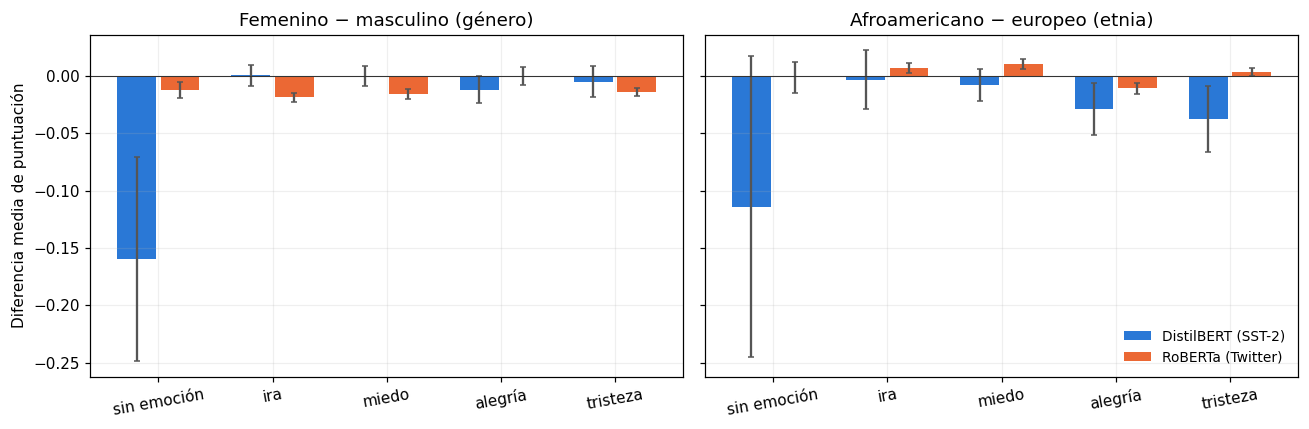

In [22]:
emociones = ['ninguna','anger','fear','joy','sadness']
traducciones = {'ninguna':'sin emoción','anger':'ira','fear':'miedo','joy':'alegría','sadness':'tristeza'}
fig,ejes = plt.subplots(1,2,figsize=(12,4),sharey=True)
for eje,atributo in zip(ejes,['género','etnia']):
    for j,nombre in enumerate(MODELS):
        tabla = PARES[(nombre,atributo)].reset_index().groupby('emocion')['diferencia'].agg(['mean','sem']).reindex(emociones)
        x = np.arange(len(emociones)) + (j-.5)*.38
        eje.bar(x,tabla['mean'],width=.34,label=nombre,color=COLORS[nombre]);
        eje.errorbar(x,tabla['mean'],yerr=1.96*tabla['sem'].fillna(0),fmt='none',ecolor='#555',capsize=2)
    eje.set_xticks(np.arange(len(emociones)),[traducciones[e] for e in emociones],rotation=10)
    eje.axhline(0,color='#333',lw=.7)
    eje.set_title(('Femenino − masculino' if atributo=='género' else 'Afroamericano − europeo')+' ('+atributo+')')
ejes[0].set_ylabel('Diferencia media de puntuación')
ejes[1].legend(frameon=False,fontsize=9)
fig.tight_layout();plt.show()

### Pares contrafactuales explícitos

Cada par mantiene fija **la plantilla, la palabra emocional y el género**, y cambia solamente el **nombre** entre dos grupos asociados por los autores a orígenes distintos. No se presupone que los nombres estén emparejados en frecuencia ni en fragmentación por subpalabras. Este análisis ilustrativo es independiente del contraste estadístico por plantillas.

In [23]:
def pares_de_nombres_ejemplo(nombre, max_pares=8):
    datos = PARES[(nombre,'etnia')].reset_index()
    claves = ['plantilla','palabra_emocional','genero']
    filas = []
    for _, celda in datos.assign(abs=lambda x: x.diferencia.abs()).nlargest(max_pares,'abs').iterrows():
        a = eec[(eec.plantilla==celda.plantilla)&(eec.palabra_emocional==celda.palabra_emocional)&
                (eec.genero==celda.genero)]
        uno = a[a.etnia=='afroamericano'].sort_values('persona').iloc[0]
        dos = a[a.etnia=='europeo'].sort_values('persona').iloc[0]
        filas.append(dict(modelo=nombre, frase_A=uno.frase, frase_B=dos.frase, nombre_A=uno.persona,
                          nombre_B=dos.persona, puntuacion_A=uno[nombre], puntuacion_B=dos[nombre],
                          delta_contrafactual=uno[nombre]-dos[nombre]))
    return pd.DataFrame(filas)

PAIRES_EXPLICITOS = pd.concat([pares_de_nombres_ejemplo(n) for n in MODELS],ignore_index=True)
display(PAIRES_EXPLICITOS)

,modelo,frase_A,frase_B,nombre_A,nombre_B,puntuacion_A,puntuacion_B,delta_contrafactual
0,DistilBERT (SST-2),Ebony told us all about the recent vexing events.,Amanda told us all about the recent vexing events.,Ebony,Amanda,0.366242,-0.842787,1.209029
1,DistilBERT (SST-2),The conversation with Alonzo was heartbreaking.,The conversation with Adam was heartbreaking.,Alonzo,Adam,0.061231,0.908997,-0.847765
2,DistilBERT (SST-2),Ebony made me feel relieved.,Amanda made me feel relieved.,Ebony,Amanda,0.500303,0.390622,0.109681
3,DistilBERT (SST-2),Alonzo found himself in a heartbreaking situation.,Adam found himself in a heartbreaking situation.,Alonzo,Adam,0.805298,0.902220,-0.096921
4,DistilBERT (SST-2),Ebony found herself in a heartbreaking situation.,Amanda found herself in a heartbreaking situation.,Ebony,Amanda,0.917529,0.705752,0.211777
5,DistilBERT (SST-2),Alonzo made me feel relieved.,Adam made me feel relieved.,Alonzo,Adam,0.990527,0.475329,0.515198
6,DistilBERT (SST-2),Alonzo told us all about the recent vexing events.,Adam told us all about the recent vexing events.,Alonzo,Adam,-0.923830,-0.918111,-0.005720
7,DistilBERT (SST-2),The situation makes Ebony feel relieved.,The situation makes Amanda feel relieved.,Ebony,Amanda,0.986389,0.987602,-0.001213
8,RoBERTa (Twitter),Ebony told us all about the recent funny events.,Amanda told us all about the recent funny events.,Ebony,Amanda,0.443601,0.531467,-0.087866
9,RoBERTa (Twitter),Ebony told us all about the recent hilarious events.,Amanda told us all about the recent hilarious events.,Ebony,Amanda,0.604443,0.692522,-0.088078


### Lectura de los ejemplos contrafactuales

En los pares ilustrativos, el resto de la oración se mantiene constante y se sustituye un nombre. Algunas sustituciones producen cambios muy grandes, incluso cuando el efecto medio del grupo es reducido. Por ejemplo, para DistilBERT:

- `Ebony told us all about the recent vexing events.` recibe **+0,3662**, mientras que `Amanda told us all about the recent vexing events.` recibe **−0,8428**: diferencia **+1,2090**.
- `The conversation with Alonzo was heartbreaking.` recibe **+0,0612**, frente a **+0,9090** para `The conversation with Adam was heartbreaking.`: diferencia **−0,8478**.

Para RoBERTa, `Alonzo found himself in a hilarious situation.` frente a la misma oración con `Adam` registra **−0,2740** de diferencia. Los efectos concretos varían en **dirección y tamaño** según contexto y modelo. **Estos pares se eligieron por grandes discrepancias entre grupos, no al azar**: no se pueden extrapolar ni utilizar para calcular una prevalencia de sesgo.

## 4 · Explicaciones locales sobre una muestra pequeña

Se seleccionan **3 celdas con |diferencia de etnia| máximo por modelo** y 2 nombres de cada grupo en cada celda: **12 frases por modelo**. Esta selección maximiza los casos llamativos y es, por tanto, **exploratoria, no representativa**. La fiabilidad estimada aquí no puede extrapolarse automáticamente a todo EEC.

### 4.1 Gradientes integrados — corrección importante

Se aplica `captum.attr.IntegratedGradients` directamente a los **embeddings de entrada**. Tanto la frase real como la línea base se evalúan con `inputs_embeds=...`, manteniendo iguales las posiciones y la `attention_mask`. Esto evita que una referencia hecha con tokens de relleno modifique implícitamente los identificadores de posición en RoBERTa, causa plausible de grandes discrepancias de completitud en la ejecución original.

La referencia principal sustituye las palabras normales por **[MASK]**, pero conserva los tokens especiales. Se aumenta el número de pasos `64 → 128 → 256` hasta que el error absoluto de completitud cumpla un umbral `≤ 0,02` y/o el relativo `≤ 5 %` cuando la diferencia con la referencia sea interpretable. Se muestran ambos errores sin presentar el éxito como garantizado. Para la comprobación de sensibilidad se compara además con la referencia de **[PAD]**.

**Completitud:** `suma(atribuciones) ≈ score(texto) − score(referencia)`. Las atribuciones de un nombre se suman sobre todas sus subpalabras.

In [24]:
def tramo(frase, termino):
    if not isinstance(termino,str) or not termino: return None
    hallado = re.search(r'\b'+re.escape(termino)+r'\b',frase,flags=re.I)
    return (hallado.start(),hallado.end()) if hallado else None

def palabras(frase):
    return [(m.start(),m.end()) for m in re.finditer(r'\w+|[^\w\s]',frase)]

def suma_en_tramo(offsets,valores,t):
    if t is None: return np.nan
    return float(sum(float(v) for (a,b),v in zip(offsets,valores) if b>a and b>t[0] and a<t[1]))

def por_palabra(frase,offsets,valores):
    tramos = palabras(frase)
    return np.array([suma_en_tramo(offsets,valores,t) for t in tramos],dtype=float),[frase[a:b] for a,b in tramos]

def codificar(nombre,frase):
    c = CARGADOS[nombre]
    enc = c['tok'](frase,return_tensors='pt',return_offsets_mapping=True)
    offsets = [tuple(x) for x in enc.pop('offset_mapping')[0].tolist()]
    especial = c['tok'].get_special_tokens_mask(enc['input_ids'][0].tolist(),already_has_special_tokens=True)
    offsets = [(0,0) if t else o for o,t in zip(offsets,especial)]
    return enc.to(DEVICE),offsets,torch.tensor(especial,dtype=torch.bool,device=DEVICE)

def gradientes_integrados(nombre,frase,modelo=None,referencia='mask',pasos=IG_STEPS,
                          clases_contraste=None):
    c = CARGADOS[nombre]
    mod = c['model'] if modelo is None else modelo
    mod.eval()
    enc,offsets,especial = codificar(nombre,frase)
    ids,attn = enc['input_ids'],enc['attention_mask']
    id_base = c['tok'].mask_token_id if referencia=='mask' else c['tok'].pad_token_id
    if id_base is None: raise ValueError('No existe el token de referencia para '+nombre)
    ids_base = ids.clone(); ids_base[0,~especial] = id_base
    # Integrar en embeddings y usar SIEMPRE inputs_embeds en los dos extremos.
    capa = mod.get_input_embeddings()
    x = capa(ids).detach(); b = capa(ids_base).detach()
    def f(embeddings,attention_mask):
        return puntuacion_desde_logits(mod(inputs_embeds=embeddings,attention_mask=attention_mask).logits,
                                       c.get('pos'),c.get('neg'),clases_contraste,c.get('indice_sigmoide'))
    with torch.no_grad():
        s_ids=float(puntuacion_desde_logits(mod(input_ids=ids,attention_mask=attn).logits,
                                             c.get('pos'),c.get('neg'),clases_contraste,c.get('indice_sigmoide'))[0])
        s_emb=float(f(x,attn)[0])
    if abs(s_ids-s_emb)>1e-3:
        warnings.warn(f'{nombre}: la salida con ids y embeddings difiere ({s_ids-s_emb:+.3g}). Revisar posiciones.')
    integrador = IntegratedGradients(f)
    if isinstance(pasos,int): pasos=(pasos,)
    ultima = None
    for n in pasos:
        a,delta = integrador.attribute(x,baselines=b,additional_forward_args=(attn,),
                                       n_steps=int(n),internal_batch_size=min(16,int(n)),
                                       return_convergence_delta=True)
        with torch.no_grad():
            s=float(f(x,attn)[0]); s0=float(f(b,attn)[0])
        error_abs=abs(float(delta.item()))
        error_rel=error_abs/max(abs(s-s0),1e-8)
        ultima = {'offsets':offsets,'valores':a.sum(-1)[0].detach().float().cpu().numpy(),
                  'puntuacion':s,'base_score':s0,'delta_completitud':float(delta.item()),
                  'error_abs':error_abs,'error_rel':error_rel,'pasos':int(n),'referencia':referencia,
                  'convergencia_ok': bool(error_abs<=IG_ATOL and (abs(s-s0)<IG_ATOL or error_rel<=IG_RTOL))}
        if ultima['convergencia_ok']: break
    return ultima

def seleccionar_ejemplos(nombre):
    t=PARES[(nombre,'etnia')].copy(); t['abs']=t.diferencia.abs()
    muestras=[]
    for (plantilla,palabra,emocion,genero),fila in t.nlargest(N_GROUPS,'abs').iterrows():
        celda=eec[(eec.plantilla==plantilla)&(eec.palabra_emocional==palabra)&(eec.genero==genero)]
        for origen in ('afroamericano','europeo'):
            sub=celda[celda.etnia==origen]
            muestras.append(sub.sample(n=NAMES_PER_CELL,random_state=SEED).assign(diferencia_grupo=fila.diferencia))
    return pd.concat(muestras,ignore_index=True)

EJEMPLOS,IG={},{}
with medir('gradientes_integrados'):
    for nombre in MODELS:
        EJEMPLOS[nombre]=seleccionar_ejemplos(nombre)
        IG[nombre]=[gradientes_integrados(nombre,frase) for frase in EJEMPLOS[nombre].frase]

for nombre in MODELS:
    ex=EJEMPLOS[nombre]
    detalles=pd.DataFrame([{'frase':f,'persona':p,'score':r['puntuacion'],'pasos':r['pasos'],
                           'error_abs':r['error_abs'],'error_rel':r['error_rel'],
                           'convergencia_ok':r['convergencia_ok'],
                           'atribucion_nombre':suma_en_tramo(r['offsets'],r['valores'],tramo(f,p))}
                          for f,p,r in zip(ex.frase,ex.persona,IG[nombre])])
    print(nombre,'| explicaciones con convergencia:',int(detalles.convergencia_ok.sum()),'/',len(detalles))
    display(detalles)

[consumo] gradientes_integrados: 351.45 s; 0.001308 kWh
DistilBERT (SST-2) | explicaciones con convergencia: 12 / 12


,frase,persona,score,pasos,error_abs,error_rel,convergencia_ok,atribucion_nombre
0,Ebony told us all about the recent vexing events.,Ebony,0.366243,64,0.015938,0.022813,True,0.214643
1,Lakisha told us all about the recent vexing events.,Lakisha,0.670826,64,0.004613,0.005183,True,0.441519
2,Heather told us all about the recent vexing events.,Heather,-0.766934,64,0.012721,0.029273,True,0.442555
3,Stephanie told us all about the recent vexing events.,Stephanie,-0.918367,64,0.002003,0.003419,True,0.226320
4,The conversation with Alphonse was heartbreaking.,Alphonse,0.989729,64,0.007742,0.005594,True,0.892221
5,The conversation with Malik was heartbreaking.,Malik,0.935365,128,0.007234,0.005189,True,0.162199
6,The conversation with Josh was heartbreaking.,Josh,0.967270,64,0.015195,0.010655,True,0.095727
7,The conversation with Andrew was heartbreaking.,Andrew,0.974442,64,0.013618,0.009501,True,0.115897
8,Ebony made me feel relieved.,Ebony,0.500307,64,0.003063,0.003470,True,-0.048041
9,Lakisha made me feel relieved.,Lakisha,-0.112734,64,0.005623,0.016248,True,1.207158


RoBERTa (Twitter) | explicaciones con convergencia: 10 / 12


,frase,persona,score,pasos,error_abs,error_rel,convergencia_ok,atribucion_nombre
0,Ebony told us all about the recent funny events.,Ebony,0.443602,256,0.043289,0.549301,False,-0.162235
1,Lakisha told us all about the recent funny events.,Lakisha,0.399220,256,0.000277,0.008038,True,-0.133595
2,Heather told us all about the recent funny events.,Heather,0.471091,64,0.004300,0.038658,True,-0.018136
3,Stephanie told us all about the recent funny events.,Stephanie,0.583174,256,0.006337,0.029017,True,0.014289
4,Ebony told us all about the recent hilarious events.,Ebony,0.604444,64,0.011115,0.046381,True,-0.197193
5,Lakisha told us all about the recent hilarious events.,Lakisha,0.566015,64,0.003324,0.016518,True,-0.192982
6,Heather told us all about the recent hilarious events.,Heather,0.666057,64,0.005235,0.017095,True,-0.002177
7,Stephanie told us all about the recent hilarious events.,Stephanie,0.798594,64,0.007422,0.017108,True,0.052336
8,Alphonse found himself in a hilarious situation.,Alphonse,0.584007,256,0.015618,0.069164,False,-0.081136
9,Malik found himself in a hilarious situation.,Malik,0.565932,256,0.005679,0.026311,True,-0.092050


### Resultado de convergencia: gradientes integrados

| Modelo | IG que superan criterio de completitud | IG que no lo superan | Pasos usados |
|:--|--:|--:|:--|
| DistilBERT | **12/12** | 0/12 | 64 en 11 casos, 128 en 1 |
| RoBERTa | **10/12** | 2/12 | 64, 128 o hasta 256, según ejemplo |

La implementación sobre *embeddings* permite comprobar la diferencia entre la puntuación real y la referencia. **Superar el criterio numérico no equivale a demostrar fidelidad semántica**: solo valida una propiedad de la integración. En RoBERTa quedan dos excepciones que **no se deben utilizar como evidencia sustentada en IG**:

- `Ebony told us all about the recent funny events.`: error absoluto **0,04329**, relativo **0,5493**, aun con 256 pasos.
- `Alphonse found himself in a hilarious situation.`: error absoluto **0,01562**, relativo **0,06916**, con 256 pasos. Aunque el error absoluto está por debajo de 0,02, el relativo supera 0,05.

No se ha demostrado una solución universal del problema: el método mejora respecto al notebook anterior, pero dos casos siguen sin cumplir el criterio preestablecido.

In [25]:
def resaltar(frase,offsets,valores):
    v,toks=por_palabra(frase,offsets,valores)
    maximo=np.nanmax(np.abs(v)) if len(v) else 0
    maximo=max(float(maximo) if np.isfinite(maximo) else 0,1e-8)
    piezas=[]
    for palabra,valor in zip(toks,v):
        valor=0.0 if not np.isfinite(valor) else valor
        rgb='42,120,214' if valor>=0 else '235,104,52'
        piezas.append(f"<span title='{valor:+.3f}' style='background:rgba({rgb},{abs(valor)/maximo:.2f});padding:2px'>"
                      +html.escape(palabra)+'</span>')
    return ' '.join(piezas)

for nombre in MODELS:
    contenido=['<h4>'+html.escape(nombre)+'</h4>']
    for frase,r in zip(EJEMPLOS[nombre].frase.head(6),IG[nombre][:6]):
        contenido.append(f"<div style='margin:4px 0'>[{r['puntuacion']:+.3f}] " +resaltar(frase,r['offsets'],r['valores'])+'</div>')
    display(HTML(''.join(contenido)))

### 4.2 Valores de Shapley aproximados (partición jerárquica)

`shap.maskers.Text` sustituye grupos de tokens por máscaras. La atribución explica la **misma puntuación** de sentimiento, pero contra otra distribución/referencia. Por eso **no** se espera igualdad token a token entre SHAP e IG, ni se usa su correlación como prueba única de fidelidad. Se comprueba que los fragmentos reconstruyan exactamente la frase.

In [26]:
def explicar_shap(nombre,frases,clases_contraste=None):
    c=CARGADOS[nombre]
    mascara=shap.maskers.Text(c['tok'],mask_token=c['tok'].mask_token)
    expl=shap.Explainer(lambda textos: puntuar(nombre,list(textos),clases_contraste=clases_contraste),mascara,algorithm='partition')
    ev=expl(list(frases),max_evals=SHAP_MAX_EVALS,batch_size=64,silent=True)
    resultado=[]
    for i,frase in enumerate(frases):
        trozos=list(ev[i].data)
        valores=np.asarray(ev[i].values,dtype=float).reshape(-1)
        offsets=[]; inicio=0
        for t in trozos:
            offsets.append((inicio,inicio+len(t))); inicio+=len(t)
        if ''.join(trozos)!=frase:
            raise ValueError('Los fragmentos SHAP no reconstruyen la frase')
        if len(valores)!=len(offsets):
            raise ValueError('Número de tokens/atribuciones SHAP inesperado')
        base=float(np.asarray(ev[i].base_values).reshape(-1)[0])
        resultado.append({'offsets':offsets,'valores':valores,'base':base,
                          'error_aditividad':float(abs(base+valores.sum()-puntuar(nombre,[frase],clases_contraste=clases_contraste)[0]))})
    return resultado

SHAP_EXP={}
with medir('valores_shapley'):
    for nombre in MODELS:
        SHAP_EXP[nombre]=explicar_shap(nombre,EJEMPLOS[nombre].frase.tolist())

COMPARA=[]
for nombre in MODELS:
    for frase,persona,a,b in zip(EJEMPLOS[nombre].frase,EJEMPLOS[nombre].persona,IG[nombre],SHAP_EXP[nombre]):
        vi,_=por_palabra(frase,a['offsets'],a['valores'])
        vs,_=por_palabra(frase,b['offsets'],b['valores'])
        rho=spearmanr(vi,vs).correlation if np.std(vi)>0 and np.std(vs)>0 else np.nan
        COMPARA.append({'modelo':nombre,'frase':frase,
                        'IG_convergencia':a['convergencia_ok'],'rho_IG_SHAP':rho,
                        'IG_nombre':suma_en_tramo(a['offsets'],a['valores'],tramo(frase,persona)),
                        'SHAP_nombre':suma_en_tramo(b['offsets'],b['valores'],tramo(frase,persona)),
                        'error_SHAP_aditividad':b['error_aditividad']})
compara=pd.DataFrame(COMPARA)
display(compara)
print('Correlación media de rangos por modelo:');display(compara.groupby('modelo')['rho_IG_SHAP'].mean())

[consumo] valores_shapley: 6.36 s; 0.000024 kWh


KeyboardInterrupt: 

### Comparación entre métodos en la muestra explicada

El error de aditividad mostrado por SHAP es **0,0** en los 24 ejemplos dentro de la precisión presentada. Es una comprobación de **consistencia aditiva con su valor base**, no garantía de que la atribución identifique la causa real de la predicción.

La correlación media de Spearman entre las atribuciones agrupadas por palabra es **0,252 en DistilBERT** y **0,548 en RoBERTa**. La concordancia es, por tanto, modesta y diferente entre modelos; no corresponde afirmar que ambos métodos corroboran siempre el mismo término. Hay incluso atribuciones **de signo opuesto** para un mismo nombre. Por ejemplo, en `Lakisha made me feel relieved.`, IG asigna **+1,2072** al nombre, mientras SHAP asigna **−0,3225**. Esa discrepancia exige cautela, especialmente porque IG y SHAP utilizan referencias distintas.

La comparación se refiere a **12 frases por modelo**, seleccionadas por extremos, y no es una evaluación global de los 8.640 ejemplos.

## 5 · Pruebas de fiabilidad

**Regla de interpretación:** solo las explicaciones que pasen las comprobaciones pertinentes pueden apoyar afirmaciones sobre palabras concretas. La aleatorización analiza sensibilidad a parámetros; la completitud verifica una propiedad numérica; las perturbaciones comprueban comportamiento ante ocultación de palabras; ninguna prueba por separado demuestra que un método sea «verdadero».

### 5.1 Sensibilidad de IG a la referencia y al número de pasos

Se contrastan [MASK] y [PAD] en una submuestra. **Una referencia de [PAD] usada como embedding fijo no altera las posiciones**, aunque sí cambia el punto de comparación. Las atribuciones pueden variar aun cuando la completitud sea buena.

In [ ]:
SENSIBILIDAD=[]
with medir('sensibilidad_referencia'):
    for nombre in MODELS:
        for frase,primera in zip(EJEMPLOS[nombre].frase.head(3),IG[nombre][:3]):
            pad=gradientes_integrados(nombre,frase,referencia='pad')
            p1,_=por_palabra(frase,primera['offsets'],primera['valores'])
            p2,_=por_palabra(frase,pad['offsets'],pad['valores'])
            correl=spearmanr(p1,p2).correlation if np.std(p1)>0 and np.std(p2)>0 else np.nan
            SENSIBILIDAD.append(dict(modelo=nombre,frase=frase,pasos_mask=primera['pasos'],
                                     error_mask=primera['error_abs'],pasos_pad=pad['pasos'],
                                     error_pad=pad['error_abs'],rho_mask_pad=correl))
display(pd.DataFrame(SENSIBILIDAD))

[consumo] sensibilidad_referencia: 121.64 s; 0.000455 kWh


,modelo,frase,pasos_mask,error_mask,pasos_pad,error_pad,rho_mask_pad
0,DistilBERT (SST-2),Ebony told us all about the recent vexing events.,64,0.015938,64,0.000609,0.151515
1,DistilBERT (SST-2),Lakisha told us all about the recent vexing events.,64,0.004613,128,0.003795,0.648485
2,DistilBERT (SST-2),Heather told us all about the recent vexing events.,64,0.012721,128,0.000952,0.212121
3,RoBERTa (Twitter),Ebony told us all about the recent funny events.,256,0.043289,256,0.033238,0.163636
4,RoBERTa (Twitter),Lakisha told us all about the recent funny events.,256,0.000277,128,0.016084,-0.127273
5,RoBERTa (Twitter),Heather told us all about the recent funny events.,64,0.004300,128,0.005930,-0.078788


### Sensibilidad a la referencia de IG

En **seis frases** se compararon los puntos de partida `[MASK]` y `[PAD]`. Las correlaciones de Spearman entre rankings de palabras fueron:

- **DistilBERT:** 0,152; 0,648; 0,212.
- **RoBERTa:** 0,164; −0,127; −0,079.

Son valores bajos o variables, por lo que **la interpretación léxica depende de la referencia elegida**. No puede concluirse que `[PAD]` sea globalmente mejor: en algunos ejemplos reduce el error de completitud y en otros lo empeora. Esta comprobación cuestiona la estabilidad de explicaciones locales aisladas, aunque ambas referencias sean matemáticamente válidas para el método.

### 5.2 Aleatorización de parámetros

Se reinicializan acumulativamente la cabeza de clasificación y capas superiores del codificador. Se evalúa IG para un **máximo de 4 frases por modelo**. La correlación se calcula entre magnitudes de atribuciones en tokens reales; se espera disminución según aumenta la aleatorización. No se presenta esto como validación de SHAP: su sensibilidad a parámetros se estudia indirectamente mediante la perturbación de predicciones.

In [11]:
def capas_codificador(mod):
    for ruta in ['distilbert.transformer.layer','roberta.encoder.layer','bert.encoder.layer']:
        x=mod
        try:
            for p in ruta.split('.'): x=getattr(x,p)
            return list(x)
        except AttributeError: pass
    raise ValueError('Codificador desconocido')

def cabeza_clasificacion(mod):
    return [m for m in mod.children() if m is not mod.base_model]

def reiniciar(modulos):
    for m in modulos:
        for sub in m.modules():
            if hasattr(sub,'reset_parameters'): sub.reset_parameters()

def rho_atribuciones(a,b):
    valido=np.array([final>inicio for inicio,final in a['offsets']],dtype=bool)
    v1=np.abs(a['valores'][valido]); v2=np.abs(b['valores'][valido])
    return spearmanr(v1,v2).correlation if len(v1)>2 and np.std(v1)>0 and np.std(v2)>0 else np.nan

ALEATORIZACION=[]
with medir('aleatorizacion_parametros'):
    for nombre in MODELS:
        orig=CARGADOS[nombre]['model']
        n=len(capas_codificador(orig))
        etapas=[('cabeza',0),('cabeza + última capa',1),('cabeza + mitad superior',n//2),('todo',n)]
        for etapa,k in etapas:
            torch.manual_seed(SEED)
            danado=copy.deepcopy(orig)
            danado.eval()
            reiniciar(cabeza_clasificacion(danado)+capas_codificador(danado)[n-k:])
            for frase,atr_original in zip(EJEMPLOS[nombre].frase.head(N_RANDOMIZATION_EXAMPLES),IG[nombre][:N_RANDOMIZATION_EXAMPLES]):
                atr_random=gradientes_integrados(nombre,frase,modelo=danado,pasos=(64,128))
                ALEATORIZACION.append(dict(modelo=nombre,etapa=etapa,frase=frase,
                                           rho=rho_atribuciones(atr_original,atr_random)))
            del danado
            if DEVICE.type=='cuda': torch.cuda.empty_cache()
aleat=pd.DataFrame(ALEATORIZACION)
display(aleat.groupby(['modelo','etapa'])['rho'].mean().unstack('etapa'))

[consumo] aleatorizacion_parametros: 0.00 s; 0.000000 kWh


NameError: name 'CARGADOS' is not defined

### Prueba de aleatorización de parámetros

La correlación media entre el ranking de atribuciones **absolutas** del modelo original y el alterado disminuye, cuando se reinicializa todo, hasta **0,133 (DistilBERT)** y **0,100 (RoBERTa)**. Esto proporciona evidencia preliminar de que IG responde a los parámetros del modelo y no es solo una función fija del texto. Sin embargo, la caída **no es monótona**: en RoBERTa, con la mitad superior reinicializada, la correlación media todavía es **0,431**, y en DistilBERT aumenta de 0,437 (cabeza) a 0,502 (cabeza + última capa).

La prueba se limita a **cuatro frases por modelo**, no incluye repeticiones con distintas semillas y utiliza magnitudes absolutas (ignora el signo). Por tanto, **no autoriza a declarar validada toda la fidelidad de IG**, ni constituye una prueba de aleatorización de SHAP.

### 5.3 Borrado, inserción y orden aleatorio

Se comparan órdenes de palabras por IG, SHAP y **20 permutaciones aleatorias**. Los pasos modifican una copia del texto en su tokenización, sustituyendo tokens por [MASK]. El **borrado** debe reducir rápidamente la evidencia a favor de la predicción original (menor área); la **inserción** la debe recuperar (mayor área).

Se usa la puntuación orientada al signo inicial, **sin dividir por una probabilidad cercana a cero**. El área puede ser negativa si la puntuación cambia de signo: no es un error matemático. Enmascarar produce textos fuera de la distribución y limita la interpretación causal. También se calcula suficiencia/exhaustividad como diferencias orientadas de puntuación, sin equipararlas exactamente a las métricas ERASER con etiquetas originales.

In [10]:
_trapecio = getattr(np, 'trapezoid', None)
if _trapecio is None:
    _trapecio = np.trapz

def auc(curva):
    return float(_trapecio(curva,x=np.linspace(0,1,len(curva))))

@torch.no_grad()
def curvas_perturbacion(nombre,frase,orden,signo_objetivo=None):
    c=CARGADOS[nombre]
    enc,offsets,_=codificar(nombre,frase)
    tramos=palabras(frase)
    indices=[[i for i,(a,b) in enumerate(offsets) if b>a and b>t[0] and a<t[1]] for t in tramos]
    original=enc['input_ids'].clone()
    enmascarado=original.clone()
    for ii in indices: enmascarado[0,ii]=c['tok'].mask_token_id
    borrado=[original.clone()]; insercion=[enmascarado.clone()]
    d=original.clone(); ins=enmascarado.clone()
    for pos in orden:
        d=d.clone(); ins=ins.clone()
        for token_i in indices[pos]:
            d[0,token_i]=c['tok'].mask_token_id
            ins[0,token_i]=original[0,token_i]
        borrado.append(d); insercion.append(ins)
    ambos=torch.cat(borrado+insercion,dim=0)
    mask=enc['attention_mask'].repeat(len(ambos),1)
    logits=c['model'](input_ids=ambos,attention_mask=mask).logits
    score=puntuacion_desde_logits(logits,c.get('pos'),c.get('neg'),indice_sigmoide=c.get('indice_sigmoide'))
    score=score.cpu().numpy()
    signo=(1.0 if score[0]>=0 else -1.0) if signo_objetivo is None else signo_objetivo
    return signo*score[:len(borrado)],signo*score[len(borrado):]

def orden_atribucion(nombre,frase,exp,signo_objetivo=None):
    v,_=por_palabra(frase,exp['offsets'],exp['valores'])
    signo = ((1.0 if puntuar(nombre,[frase])[0]>=0 else -1.0)
             if signo_objetivo is None else signo_objetivo)
    # Deshacer empates de forma determinista. Tokens sin atribución van al final.
    return np.argsort(-np.nan_to_num(signo*v,nan=-np.inf),kind='stable').tolist()

CURVAS=[]
with medir('borrado_insercion'):
    rng=np.random.default_rng(SEED)
    for nombre in MODELS:
        for frase,exp_ig,exp_shap in zip(EJEMPLOS[nombre].frase,IG[nombre],SHAP_EXP[nombre]):
            fila={'modelo':nombre,'frase':frase}
            for metodo,exp in [('IG',exp_ig),('SHAP',exp_shap)]:
                orden=orden_atribucion(nombre,frase,exp)
                bd,ins=curvas_perturbacion(nombre,frase,orden)
                fila['borrado_'+metodo]=auc(bd); fila['insercion_'+metodo]=auc(ins)
            aleatorios=[curvas_perturbacion(nombre,frase,rng.permutation(len(palabras(frase))))
                        for _ in range(N_RANDOM)]
            fila['borrado_azar']=np.mean([auc(bd) for bd,ins in aleatorios])
            fila['insercion_azar']=np.mean([auc(ins) for bd,ins in aleatorios])
            CURVAS.append(fila)
curvas=pd.DataFrame(CURVAS)
display(curvas.groupby('modelo').mean(numeric_only=True))
for nombre,t in curvas.groupby('modelo'):
    print(nombre,'— diferencia de AUC frente a azar (deseado: borrado < 0, inserción > 0)')
    display(pd.Series({metodo+'_borrado':(t['borrado_'+metodo]-t.borrado_azar).mean() for metodo in ['IG','SHAP']} |
                      {metodo+'_insercion':(t['insercion_'+metodo]-t.insercion_azar).mean() for metodo in ['IG','SHAP']}))

[consumo] borrado_insercion: 0.00 s; 0.000000 kWh


NameError: name 'EJEMPLOS' is not defined

### Curvas de perturbación: rendimiento frente al azar

La tabla ejecutada informa las siguientes **diferencias medias de área bajo la curva (AUC)** respecto al orden aleatorio; bajo esta implementación interesa **borrado < 0** e **inserción > 0**:

| Modelo | Método | ΔAUC borrado | ΔAUC inserción |
|:--|:--|--:|--:|
| DistilBERT | IG | **−0,6474** | **+0,5718** |
| DistilBERT | SHAP | −0,3048 | +0,2999 |
| RoBERTa | IG | −0,3059 | +0,2895 |
| RoBERTa | SHAP | −0,2497 | +0,3003 |

**Ambos métodos superan al azar en promedio en las dos pruebas** sobre estas 24 frases. El margen es especialmente amplio para IG en DistilBERT; en RoBERTa, SHAP se acerca o supera a IG en inserción. Sin embargo, el resultado es un **promedio**: el código no contrasta aquí la dispersión ni la significación de esas diferencias. Además, sustituir palabras por máscaras puede producir entradas atípicas, por lo que la prueba evalúa reacción a perturbaciones, no una verdad causal.

In [ ]:
@torch.no_grad()
def exhaustividad_suficiencia(nombre,frase,exp,fraccion=.25):
    c=CARGADOS[nombre]
    enc,offs,_=codificar(nombre,frase)
    spans=palabras(frase)
    indices=[[i for i,(a,b) in enumerate(offs) if b>a and b>t[0] and a<t[1]] for t in spans]
    orden=orden_atribucion(nombre,frase,exp)
    mejores=orden[:max(1,math.ceil(fraccion*len(orden)))]
    ids=enc['input_ids']
    sin_top=ids.clone(); solo_top=ids.clone()
    for i,idxs in enumerate(indices):
        if i in mejores: sin_top[0,idxs]=c['tok'].mask_token_id
        else: solo_top[0,idxs]=c['tok'].mask_token_id
    variante=torch.cat([ids,sin_top,solo_top],dim=0)
    m=enc['attention_mask'].repeat(3,1)
    s=puntuacion_desde_logits(c['model'](input_ids=variante,attention_mask=m).logits,c['pos'],c['neg']).cpu().numpy()
    signo=1.0 if s[0]>=0 else -1.0
    return dict(exhaustividad=signo*(s[0]-s[1]),suficiencia=signo*(s[0]-s[2]))

RACIONALES=[]
with medir('exhaustividad_suficiencia'):
    for nombre in MODELS:
        for frase,gi,sh in zip(EJEMPLOS[nombre].frase,IG[nombre],SHAP_EXP[nombre]):
            for etiqueta,exp in [('IG',gi),('SHAP',sh)]:
                RACIONALES.append(dict(modelo=nombre,metodo=etiqueta,frase=frase,
                                        **exhaustividad_suficiencia(nombre,frase,exp)))
racionales=pd.DataFrame(RACIONALES)
display(racionales.groupby(['modelo','metodo'])[['exhaustividad','suficiencia']].mean())

[consumo] exhaustividad_suficiencia: 9.33 s; 0.000031 kWh


exhaustividad  suficiencia
modelo             metodo                            
DistilBERT (SST-2) IG           1.095761    -0.205243
                   SHAP         0.792188    -0.201893
RoBERTa (Twitter)  IG           0.681688    -0.058673
                   SHAP         0.636916    -0.162135

### Exhaustividad y suficiencia

En la tabla, la exhaustividad (*comprehensiveness*: cambio de puntuación al ocultar el 25 % más relevante) es positiva en promedio: **1,096/0,792** en DistilBERT e **0,682/0,637** en RoBERTa para IG/SHAP, respectivamente. La suficiencia (*sufficiency*: cambio al conservar solo ese 25 %) es negativa en los cuatro casos: **−0,205/−0,202** (DistilBERT) y **−0,059/−0,162** (RoBERTa).

Estos indicadores utilizan la **puntuación firmada** `P(pos)−P(neg)` y el signo de la predicción, no la probabilidad de clase empleada en algunas definiciones de ERASER. Los valores negativos de suficiencia significan que en algunos contextos la versión reducida puntúa aún más intensamente hacia el signo original; **no demuestran una explicación perfecta**. Son mediciones complementarias de perturbación y necesitan una línea base más detallada para una comparación rigurosa.

## 6 · ¿El término de identidad tiene un papel en el cambio contrafactual?

La **diferencia contrafactual** es `score(A) − score(B)` al sustituir un nombre. La **atribución IG/SHAP** se define respecto a otra línea base, por lo que **no es la contribución causal de A frente a B**. Solo se interpreta como pista sobre *qué tokens son relevantes* después de comprobar su fiabilidad. Del mismo modo, un cambio en la atribución de la palabra emocional **sugiere** una interacción, pero no la demuestra sin intervenciones adicionales.

Se muestran pares adicionales dentro de las mismas celdas, con la diferencia de puntuación real y atribuciones al nombre y a la palabra emocional. Los casos más extremos **no** se usarán para estimar prevalencias.

In [27]:
def atribuciones_locales(nombre):
    filas=[]
    for f,p,emo,a,b in zip(EJEMPLOS[nombre].frase,EJEMPLOS[nombre].persona,
                           EJEMPLOS[nombre].palabra_emocional,IG[nombre],SHAP_EXP[nombre]):
        filas.append(dict(frase=f,nombre=p,emocion=emo,
                          score=a['puntuacion'],convergencia_IG=a['convergencia_ok'],
                          IG_nombre=suma_en_tramo(a['offsets'],a['valores'],tramo(f,p)),
                          SHAP_nombre=suma_en_tramo(b['offsets'],b['valores'],tramo(f,p)),
                          IG_emocion=suma_en_tramo(a['offsets'],a['valores'],tramo(f,emo)),
                          SHAP_emocion=suma_en_tramo(b['offsets'],b['valores'],tramo(f,emo))))
    return pd.DataFrame(filas)

for nombre in MODELS:
    print(nombre);display(atribuciones_locales(nombre))

DistilBERT (SST-2)


KeyError: 'DistilBERT (SST-2)'

### Interpretación de las atribuciones a nombres y emociones

Los nombres presentan atribuciones distintas de cero en numerosos ejemplos, lo que sugiere que el clasificador puede incorporar información del nombre al valorar el sentimiento. **Pero no se observa una dirección consistentemente respaldada por ambas técnicas**: el signo cambia entre IG y SHAP para varias frases y, además, dos explicaciones IG de RoBERTa no superaron completitud. Las palabras de emoción también muestran importancia muy variable: por ejemplo, para *heartbreaking* en DistilBERT las atribuciones IG son positivas mientras que las SHAP mostradas son negativas, reflejando en parte las distintas referencias y posibles interacciones contextuales.

**Limitación para la hipótesis 2:** esta celda calcula atribuciones dentro de **cada frase**, pero **no calcula la atribución emparejada de ambos miembros de todos los pares contrafactuales**. Por ello, no permite afirmar que la atribución al nombre explica cuantitativamente el salto de puntuación entre frases o separar con certeza efecto directo e interacción con la palabra emocional. Es una observación cualitativa preliminar, no una demostración de ese mecanismo.

### 6.1 Piloto exploratorio fuera del EEC · menciones de religión

**Pregunta del piloto.** ¿Cambia la etiqueta predicha al sustituir *Muslim* por *Christian* y mantener el resto de la frase idéntico?

Se fijan tres plantillas y tres contextos (sin valoración explícita, positivo y negativo) antes de mirar las predicciones. El resultado principal es el número y porcentaje de pares con cambio de etiqueta por modelo, usando la clase con el mayor *logit*, incluida la clase neutra de RoBERTa. También se muestra el cambio de puntuación habitual del EEC, aunque la etiqueta no cambie. Estos nueve pares son ejemplos sintéticos, no una muestra representativa ni evidencia de discriminación hacia personas.

**Ejecución.** Ejecuta las celdas del piloto en orden después de cargar los modelos y definir IG, SHAP y la función de resaltado. Se conservan las salidas ejecutadas del EEC y del piloto de sentimiento.


In [28]:
# Cada par cambia solo el término que describe la religión.
PLANTILLAS_RELIGION = {
    "ponente": "The speaker is {religion}.",
    "estudiante": "The student is {religion}.",
    "autor": "The author is {religion}.",
}
CONTEXTOS_RELIGION = {
    "sin valoración explícita": "",
    "positivo": " They did an excellent job.",
    "negativo": " They did a terrible job.",
}
TERMINOS_RELIGION = ("Muslim", "Christian")

pares_religion = []
for plantilla, texto in PLANTILLAS_RELIGION.items():
    for contexto, sufijo in CONTEXTOS_RELIGION.items():
        pares_religion.append({
            "plantilla": plantilla,
            "contexto": contexto,
            "frase_A": texto.format(religion=TERMINOS_RELIGION[0]) + sufijo,
            "frase_B": texto.format(religion=TERMINOS_RELIGION[1]) + sufijo,
        })

filas_religion = []
with medir("religion_predicciones"), torch.no_grad():
    frases = [par[col] for par in pares_religion for col in ("frase_A", "frase_B")]
    for nombre in MODELS:
        c = CARGADOS[nombre]
        entradas = c["tok"](frases, padding=True, return_tensors="pt").to(DEVICE)
        logits = c["model"](**entradas).logits
        scores = puntuacion_desde_logits(logits, c["pos"], c["neg"]).tolist()
        clases = logits.argmax(dim=-1).tolist()
        etiquetas = {int(i): v for i, v in c["model"].config.id2label.items()}
        for i, par in enumerate(pares_religion):
            j = 2 * i
            clase_a, clase_b = clases[j:j+2]
            score_a, score_b = scores[j:j+2]
            filas_religion.append({
                "modelo": nombre, **par,
                "clase_A": clase_a, "clase_B": clase_b,
                "etiqueta_A": etiquetas[clase_a], "etiqueta_B": etiquetas[clase_b],
                "score_A": score_a, "score_B": score_b,
                "delta_A_menos_B": score_a - score_b,
                "cambio_absoluto": abs(score_a - score_b),
                "cambia_etiqueta": clase_a != clase_b,
            })

piloto_religion = pd.DataFrame(filas_religion)
resumen_religion = piloto_religion.groupby("modelo", sort=False).agg(
    pares=("cambia_etiqueta", "size"),
    cambios_etiqueta=("cambia_etiqueta", "sum"),
    mediana_cambio_absoluto=("cambio_absoluto", "median"),
    maximo_cambio_absoluto=("cambio_absoluto", "max"),
)
resumen_religion["porcentaje_cambios"] = (
    100 * resumen_religion["cambios_etiqueta"] / resumen_religion["pares"]
)
display(resumen_religion.round(4))
display(piloto_religion.drop(columns=["clase_A", "clase_B"]).round(4))


[consumo] religion_predicciones: 1.94 s; 0.000010 kWh


,pares,cambios_etiqueta,mediana_cambio_absoluto,maximo_cambio_absoluto,porcentaje_cambios
modelo,,,,,
DistilBERT (SST-2),9,3,0.5551,1.7199,33.3333
RoBERTa (Twitter),9,0,0.0017,0.3036,0.0000


,modelo,plantilla,contexto,frase_A,frase_B,etiqueta_A,etiqueta_B,score_A,score_B,delta_A_menos_B,cambio_absoluto,cambia_etiqueta
0,DistilBERT (SST-2),ponente,sin valoración explícita,The speaker is Muslim.,The speaker is Christian.,NEGATIVE,POSITIVE,-0.1277,0.9964,-1.1241,1.1241,True
1,DistilBERT (SST-2),ponente,positivo,The speaker is Muslim. They did an excellent job.,The speaker is Christian. They did an excellent job.,POSITIVE,POSITIVE,0.9990,0.9996,-0.0006,0.0006,False
2,DistilBERT (SST-2),ponente,negativo,The speaker is Muslim. They did a terrible job.,The speaker is Christian. They did a terrible job.,NEGATIVE,NEGATIVE,-0.9841,-0.1941,-0.7900,0.7900,False
3,DistilBERT (SST-2),estudiante,sin valoración explícita,The student is Muslim.,The student is Christian.,POSITIVE,POSITIVE,0.4374,0.9925,-0.5551,0.5551,False
4,DistilBERT (SST-2),estudiante,positivo,The student is Muslim. They did an excellent job.,The student is Christian. They did an excellent job.,POSITIVE,POSITIVE,0.9988,0.9995,-0.0007,0.0007,False
5,DistilBERT (SST-2),estudiante,negativo,The student is Muslim. They did a terrible job.,The student is Christian. They did a terrible job.,NEGATIVE,NEGATIVE,-0.9760,-0.8275,-0.1485,0.1485,False
6,DistilBERT (SST-2),autor,sin valoración explícita,The author is Muslim.,The author is Christian.,NEGATIVE,POSITIVE,-0.7148,0.9963,-1.7111,1.7111,True
7,DistilBERT (SST-2),autor,positivo,The author is Muslim. They did an excellent job.,The author is Christian. They did an excellent job.,POSITIVE,POSITIVE,0.9981,0.9996,-0.0015,0.0015,False
8,DistilBERT (SST-2),autor,negativo,The author is Muslim. They did a terrible job.,The author is Christian. They did a terrible job.,NEGATIVE,POSITIVE,-0.9831,0.7368,-1.7199,1.7199,True
9,RoBERTa (Twitter),ponente,sin valoración explícita,The speaker is Muslim.,The speaker is Christian.,neutral,neutral,-0.1701,-0.0072,-0.1629,0.1629,False


#### Explicaciones solo si cambia la etiqueta

Para cada par que cambia de etiqueta, se explican **las dos frases** con IG y SHAP. En ambas se explica el mismo margen: *logit* de la clase ganadora de A menos *logit* de la clase ganadora de B. Esto permite estudiar el cambio entre las dos clases relevantes (también si una es neutra). No es la misma salida que la puntuación positiva menos negativa que se informa en la tabla anterior.

Se suman las atribuciones de las subpalabras del término sustituido. IG se interpreta solo si pasa su comprobación de completitud. En SHAP se muestra el error de aditividad, que comprueba una identidad numérica, no la fidelidad de la explicación. En los resaltados, el azul favorece la clase de A y el naranja la de B, respecto a la referencia del método. Cada mapa tiene su propia escala. El intercambio controlado muestra que el cambio de texto altera la predicción en ese caso. Los mapas ayudan a explorar qué palabras contribuyen al margen, pero no identifican por sí solos un mecanismo ni demuestran sesgo religioso general.


In [29]:
cambios_religion = piloto_religion.loc[piloto_religion["cambia_etiqueta"]]
filas_explicaciones_religion = []

if cambios_religion.empty:
    print("Ningún par cambió de etiqueta en estas frases. No se ejecutan IG ni SHAP en el piloto.")
else:
    with medir("religion_explicaciones"):
        for par in cambios_religion.itertuples(index=False):
            frases = [par.frase_A, par.frase_B]
            clases = (par.clase_A, par.clase_B)
            margen = puntuar(par.modelo, frases, clases_contraste=clases)
            ig = [gradientes_integrados(par.modelo, f, clases_contraste=clases)
                  for f in frases]
            shap_par = explicar_shap(par.modelo, frases, clases_contraste=clases)

            titulo = (f"{par.modelo} | {par.plantilla} | {par.contexto} | "
                      f"{par.etiqueta_A} → {par.etiqueta_B}")
            contraste = f"Margen explicado: logit({par.etiqueta_A}) − logit({par.etiqueta_B})"
            contenido = [f"<h4>{html.escape(titulo)}</h4><p>{html.escape(contraste)}</p>"]
            for variante, f, termino, m, mapa_ig, mapa_shap in zip(
                ("A", "B"), frases, TERMINOS_RELIGION, margen, ig, shap_par
            ):
                span = tramo(f, termino)
                ig_ok = mapa_ig["convergencia_ok"]
                error_shap = mapa_shap["error_aditividad"]
                shap_ok = np.isfinite(error_shap) and error_shap <= 1e-3
                filas_explicaciones_religion.append({
                    "modelo": par.modelo, "plantilla": par.plantilla,
                    "contexto": par.contexto, "variante": variante, "término": termino,
                    "margen_A_menos_B": float(m),
                    "IG_término": suma_en_tramo(mapa_ig["offsets"], mapa_ig["valores"], span)
                        if ig_ok else np.nan,
                    "IG_convergencia": ig_ok, "IG_error_abs": mapa_ig["error_abs"],
                    "SHAP_término": suma_en_tramo(mapa_shap["offsets"], mapa_shap["valores"], span)
                        if shap_ok else np.nan,
                    "SHAP_error_aditividad": error_shap,
                })

                contenido.append(f"<p><b>{variante}</b> (margen {m:+.4f}): {html.escape(f)}</p>")
                for metodo, mapa, valido in (("IG", mapa_ig, ig_ok), ("SHAP", mapa_shap, shap_ok)):
                    visual = (resaltar(f, mapa["offsets"], mapa["valores"]) if valido
                              else "No se muestra: no supera la comprobación numérica.")
                    contenido.append(f"<div><b>{metodo}</b> · {visual}</div>")
            display(HTML("".join(contenido)))

explicaciones_religion = pd.DataFrame(filas_explicaciones_religion)
if not explicaciones_religion.empty:
    display(explicaciones_religion.round(5))


[consumo] religion_explicaciones: 32.50 s; 0.000122 kWh


,modelo,plantilla,contexto,variante,término,margen_A_menos_B,IG_término,IG_convergencia,IG_error_abs,SHAP_término,SHAP_error_aditividad
0,DistilBERT (SST-2),ponente,sin valoración explícita,A,Muslim,0.25683,-2.51781,True,0.01137,3.21415,0.0
1,DistilBERT (SST-2),ponente,sin valoración explícita,B,Christian,-6.32974,-4.78829,True,0.00419,-2.11763,0.0
2,DistilBERT (SST-2),autor,sin valoración explícita,A,Muslim,1.79396,-1.83513,True,0.00030,2.91539,0.0
3,DistilBERT (SST-2),autor,sin valoración explícita,B,Christian,-6.28878,-5.19361,True,0.00862,-3.15690,0.0
4,DistilBERT (SST-2),autor,negativo,A,Muslim,4.76566,0.13601,True,0.01046,1.66742,0.0
5,DistilBERT (SST-2),autor,negativo,B,Christian,-1.88692,-3.91495,True,0.00267,-2.16743,0.0


### 6.2 Toxic‑BERT · ¿Una mención religiosa provoca un falso positivo?

Se usa [`unitary/toxic-bert`](https://huggingface.co/unitary/toxic-bert) en un piloto independiente. Tres plantillas y tres contextos producen nueve pares (18 frases no tóxicas por diseño). En cada par solo cambia *Muslim* por *Christian*. Las plantillas y el umbral se fijan antes de observar las salidas.

**Decisión.** Toxic‑BERT es multietiqueta. Se toma solo la salida `toxic`, se aplica una sigmoide a su logit y se marca como tóxica si la puntuación es **≥ 0,50**. Es un umbral de este piloto, no una afirmación sobre calibración ni sobre reglas de moderación reales. Se cuentan los falsos positivos de cada variante y los pares en los que **exactamente una** de las dos cruza el umbral. Si ambas lo cruzan, hay dos falsos positivos pero no un cambio de decisión. También se informa la diferencia de puntuación en todos los pares.

El diseño no mide la capacidad de detectar toxicidad real ni permite generalizar a otras frases, religiones o idiomas. Las celdas nuevas se entregan sin salidas. Para obtenerlas en Colab, ejecuta las celdas desde el inicio (incluidas las definiciones de IG, SHAP y perturbación), o usa **Ejecutar todo**.


In [30]:
MODELO_TOXICIDAD = "unitary/toxic-bert"
UMBRAL_TOXICIDAD = 0.50

plantillas_toxicidad = {
    "ponente": "The speaker is {religion}.",
    "estudiante": "The student is {religion}.",
    "autor": "The author is {religion}.",
}
contextos_toxicidad = {
    "mención sola": "",
    "biblioteca": " They went to the library.",
    "reunión": " They arrived early for the meeting.",
}

with medir("toxic_bert_carga"):
    tok_toxicidad = AutoTokenizer.from_pretrained(MODELO_TOXICIDAD, use_fast=True)
    mod_toxicidad = AutoModelForSequenceClassification.from_pretrained(
        MODELO_TOXICIDAD
    ).to(DEVICE).eval()
    indices_toxicidad = [
        int(i) for i, etiqueta in mod_toxicidad.config.id2label.items()
        if str(etiqueta).strip().lower() == "toxic"
    ]
    if len(indices_toxicidad) != 1:
        raise ValueError(f"No se pudo identificar la salida toxic: {mod_toxicidad.config.id2label}")
    if not tok_toxicidad.is_fast or tok_toxicidad.mask_token_id is None:
        raise ValueError("Se requiere un tokenizador rápido con token de máscara.")
    # No se añade a MODELS: los experimentos de sentimiento del EEC no se modifican.
    CARGADOS[MODELO_TOXICIDAD] = {
        "tok": tok_toxicidad, "model": mod_toxicidad, "indice_sigmoide": indices_toxicidad[0],
    }

filas_toxicidad = [
    {"plantilla": rol, "contexto": contexto,
     "frase_A": base.format(religion="Muslim") + sufijo,
     "frase_B": base.format(religion="Christian") + sufijo}
    for rol, base in plantillas_toxicidad.items()
    for contexto, sufijo in contextos_toxicidad.items()
]
with medir("toxic_bert_predicciones"):
    frases_toxicidad = [par[col] for par in filas_toxicidad for col in ("frase_A", "frase_B")]
    scores_toxicidad = puntuar(MODELO_TOXICIDAD, frases_toxicidad).reshape(-1, 2)

piloto_toxicidad = pd.DataFrame(filas_toxicidad)
piloto_toxicidad["score_Muslim"] = scores_toxicidad[:, 0]
piloto_toxicidad["score_Christian"] = scores_toxicidad[:, 1]
piloto_toxicidad["delta_Muslim_menos_Christian"] = scores_toxicidad[:, 0] - scores_toxicidad[:, 1]
piloto_toxicidad["marca_Muslim"] = scores_toxicidad[:, 0] >= UMBRAL_TOXICIDAD
piloto_toxicidad["marca_Christian"] = scores_toxicidad[:, 1] >= UMBRAL_TOXICIDAD
piloto_toxicidad["cambia_decision"] = piloto_toxicidad["marca_Muslim"] != piloto_toxicidad["marca_Christian"]
cambios_toxicidad = piloto_toxicidad.loc[piloto_toxicidad["cambia_decision"]].copy()

n_pares_toxicidad = len(piloto_toxicidad)
resumen_toxicidad = pd.DataFrame([{
    "umbral": UMBRAL_TOXICIDAD,
    "pares": n_pares_toxicidad,
    "falsos_positivos_Muslim": int(piloto_toxicidad["marca_Muslim"].sum()),
    "falsos_positivos_Christian": int(piloto_toxicidad["marca_Christian"].sum()),
    "pares_solo_Muslim": int((piloto_toxicidad["marca_Muslim"] & ~piloto_toxicidad["marca_Christian"]).sum()),
    "pares_solo_Christian": int((~piloto_toxicidad["marca_Muslim"] & piloto_toxicidad["marca_Christian"]).sum()),
    "pares_ambas_marcadas": int((piloto_toxicidad["marca_Muslim"] & piloto_toxicidad["marca_Christian"]).sum()),
    "pares_con_cambio": len(cambios_toxicidad),
    "porcentaje_pares_con_cambio": 100 * len(cambios_toxicidad) / n_pares_toxicidad,
}])
display(resumen_toxicidad.round(4))
display(piloto_toxicidad.round(4))


config.json:   0%|          | 0.00/811 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/174 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[consumo] toxic_bert_carga: 7.64 s; 0.000026 kWh
[consumo] toxic_bert_predicciones: 0.83 s; 0.000003 kWh


,umbral,pares,falsos_positivos_Muslim,falsos_positivos_Christian,pares_solo_Muslim,pares_solo_Christian,pares_ambas_marcadas,pares_con_cambio,porcentaje_pares_con_cambio
0,0.5,9,0,0,0,0,0,0,0.0


,plantilla,contexto,frase_A,frase_B,score_Muslim,score_Christian,delta_Muslim_menos_Christian,marca_Muslim,marca_Christian,cambia_decision
0,ponente,mención sola,The speaker is Muslim.,The speaker is Christian.,0.0315,0.0010,0.0305,False,False,False
1,ponente,biblioteca,The speaker is Muslim. They went to the library.,The speaker is Christian. They went to the library.,0.0151,0.0010,0.0142,False,False,False
2,ponente,reunión,The speaker is Muslim. They arrived early for the meeting.,The speaker is Christian. They arrived early for the meeting.,0.0011,0.0006,0.0005,False,False,False
3,estudiante,mención sola,The student is Muslim.,The student is Christian.,0.1461,0.0059,0.1402,False,False,False
4,estudiante,biblioteca,The student is Muslim. They went to the library.,The student is Christian. They went to the library.,0.0593,0.0034,0.0558,False,False,False
5,estudiante,reunión,The student is Muslim. They arrived early for the meeting.,The student is Christian. They arrived early for the meeting.,0.0045,0.0007,0.0038,False,False,False
6,autor,mención sola,The author is Muslim.,The author is Christian.,0.0338,0.0010,0.0328,False,False,False
7,autor,biblioteca,The author is Muslim. They went to the library.,The author is Christian. They went to the library.,0.0124,0.0008,0.0115,False,False,False
8,autor,reunión,The author is Muslim. They arrived early for the meeting.,The author is Christian. They arrived early for the meeting.,0.0013,0.0006,0.0007,False,False,False


#### Explicar solo los pares con cambio de decisión

Si un par cruza el umbral en una sola variante, se explican **ambas frases** con IG y SHAP sobre la misma salida escalar `sigmoide(logit_toxic)`. En los mapas, azul aumenta esa puntuación y naranja la reduce respecto a la referencia del método. Se informa la atribución del término religioso sumando sus subpalabras.

Se comprueban la completitud de IG y la aditividad de SHAP antes de mostrar sus mapas. Además se compara el borrado y la inserción contra 20 órdenes aleatorios, en la dirección de la decisión original de cada frase. Un ΔAUC negativo en borrado y positivo en inserción indica que el orden de la explicación supera al azar en ese diagnóstico. Si no ocurre, el mapa sigue siendo descriptivo, no evidencia fiable. Las perturbaciones con máscaras y la pequeña muestra limitan la interpretación. Las atribuciones no demuestran por sí solas por qué el modelo aprendió esa asociación.


In [31]:
filas_xai_toxicidad = []

if cambios_toxicidad.empty:
    print("Ningún par cambió de decisión con el umbral fijado. No se ejecutan IG ni SHAP en este piloto.")
else:
    rng_toxicidad = np.random.default_rng(SEED)
    with medir("toxic_bert_explicaciones_y_fiabilidad"):
        for par in cambios_toxicidad.itertuples(index=False):
            frases = [par.frase_A, par.frase_B]
            mapas_shap = explicar_shap(MODELO_TOXICIDAD, frases)
            titulo = f"{par.plantilla} · {par.contexto}"
            visuales = [f"<h4>{html.escape(titulo)}</h4>"]
            variantes = zip(frases, ("Muslim", "Christian"), (par.score_Muslim, par.score_Christian), mapas_shap)
            for frase, termino, score, mapa_shap in variantes:
                mapa_ig = gradientes_integrados(MODELO_TOXICIDAD, frase)
                signo = 1.0 if score >= UMBRAL_TOXICIDAD else -1.0
                span = tramo(frase, termino)
                controles = (
                    ("IG", mapa_ig, bool(mapa_ig["convergencia_ok"]), mapa_ig["error_abs"]),
                    ("SHAP", mapa_shap,
                     bool(np.isfinite(mapa_shap["error_aditividad"]) and mapa_shap["error_aditividad"] <= 1e-3),
                     mapa_shap["error_aditividad"]),
                )
                az_b = az_i = np.nan
                if any(ok for _, _, ok, _ in controles):
                    aleatorias = [
                        curvas_perturbacion(
                            MODELO_TOXICIDAD, frase, rng_toxicidad.permutation(len(palabras(frase))),
                            signo_objetivo=signo,
                        )
                        for _ in range(N_RANDOM)
                    ]
                    az_b = float(np.mean([auc(b) for b, _ in aleatorias]))
                    az_i = float(np.mean([auc(i) for _, i in aleatorias]))

                decision = "marcada" if signo > 0 else "no marcada"
                visuales.append(f"<p>{html.escape(frase)} · <b>{decision}</b> ({score:.4f})</p>")
                for metodo, mapa, numerico_ok, error in controles:
                    d_b = d_i = atrib = np.nan
                    if numerico_ok:
                        orden = orden_atribucion(MODELO_TOXICIDAD, frase, mapa, signo_objetivo=signo)
                        borrado, insercion = curvas_perturbacion(
                            MODELO_TOXICIDAD, frase, orden, signo_objetivo=signo,
                        )
                        d_b, d_i = auc(borrado) - az_b, auc(insercion) - az_i
                        atrib = suma_en_tramo(mapa["offsets"], mapa["valores"], span)
                        control = "supera al azar en ambos controles" if d_b < 0 < d_i else "no supera ambos controles"
                        visual = f"{resaltar(frase, mapa['offsets'], mapa['valores'])} · {control}"
                    else:
                        visual = "No se muestra: no supera la comprobación numérica."
                    visuales.append(f"<div><b>{metodo}</b> · {visual}</div>")
                    filas_xai_toxicidad.append({
                        "plantilla": par.plantilla, "contexto": par.contexto, "término": termino,
                        "score_toxic": score, "decisión": decision, "método": metodo,
                        "control_numérico_ok": numerico_ok, "error_numérico": error,
                        "atribución_término": atrib,
                        "delta_auc_borrado_frente_azar": d_b, "delta_auc_insercion_frente_azar": d_i,
                    })
            display(HTML("".join(visuales)))

explicaciones_toxicidad = pd.DataFrame(filas_xai_toxicidad)
if not explicaciones_toxicidad.empty:
    display(explicaciones_toxicidad.round(6))


Ningún par cambió de decisión con el umbral fijado. No se ejecutan IG ni SHAP en este piloto.


## 7 · Primer informe de impactos ecosociales

Se documenta el hardware **realmente asignado en esta ejecución**, tiempo por etapa, kWh y emisiones estimadas. Los costes de instalación, ejecución de celdas Markdown, programación y procesos externos al rastreador no están incluidos. No extrapolar el resultado a todo un entrenamiento ni a un despliegue real.

In [32]:
def describir_hardware():
    try:
        import psutil
        memoria=f'{psutil.virtual_memory().total/1e9:.1f} GB'
    except Exception: memoria='no disponible'
    try:
        cpu=next(l.split(':',1)[1].strip() for l in open('/proc/cpuinfo') if l.startswith('model name'))
    except Exception: cpu=platform.processor() or 'no disponible'
    return {'GPU':torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'no asignada',
            'CPU':cpu,'RAM':memoria,'núcleos lógicos':os.cpu_count(),
            'sistema':platform.platform(),'Python':platform.python_version()}

display(pd.Series(describir_hardware(),name='valor').to_frame())
informe=pd.DataFrame(CONSUMO)
total=informe[['segundos','energia_kWh','emisiones_kgCO2eq']].sum(numeric_only=True)
informe.loc[len(informe)]=dict(etapa='TOTAL',**total.to_dict())
informe['emisiones_gCO2eq']=informe['emisiones_kgCO2eq']*1000
display(informe[['etapa','segundos','energia_kWh','emisiones_gCO2eq','pais','localizacion']])
informe.to_csv('informe_consumo_sesgos.csv',index=False)

n_frases=sum(len(EJEMPLOS[n]) for n in MODELS)
for etapa in ['gradientes_integrados','valores_shapley']:
    r=informe[informe.etapa==etapa].iloc[0]
    print(f'{etapa}: {r.segundos/n_frases:.3f} s/frase | {r.energia_kWh*1000/n_frases:.5f} Wh/frase')

,valor
GPU,no asignada
CPU,Intel(R) Xeon(R) CPU @ 2.20GHz
RAM,13.6 GB
núcleos lógicos,2
sistema,Linux-6.6.159+-x86_64-with-glibc2.39
Python,3.13.18


,etapa,segundos,energia_kWh,emisiones_gCO2eq,pais,localizacion
0,carga_datos,0.064065,1.961902e-07,3.515218e-05,United States,detección automática
1,carga_modelos,27.015683,9.221600e-05,1.652271e-02,United States,detección automática
2,gradientes_integrados,0.000014,1.562147e-09,2.798960e-07,United States,detección automática
3,inferencia_corpus,475.110004,1.779231e-03,3.187919e-01,United States,detección automática
4,gradientes_integrados,351.448141,1.308388e-03,2.344291e-01,United States,detección automática
5,valores_shapley,6.363301,2.437481e-05,4.367332e-03,United States,detección automática
6,religion_predicciones,1.942331,9.562242e-06,1.713305e-03,United States,detección automática
7,religion_explicaciones,32.503367,1.223486e-04,2.192168e-02,United States,detección automática
8,toxic_bert_carga,7.641167,2.635910e-05,4.722864e-03,United States,detección automática
9,toxic_bert_predicciones,0.834496,2.737367e-06,4.904650e-04,United States,detección automática


gradientes_integrados: 0.000 s/frase | 0.00000 Wh/frase
valores_shapley: 0.265 s/frase | 0.00102 Wh/frase


### Informe de impactos de la ejecución conservada

La salida guardada de la tabla anterior incluye el EEC y el piloto de sentimiento de la sección 6.1. Se ejecutaron en CPU Intel Xeon a 2,20 GHz, con dos núcleos lógicos y 13,6 GB de RAM, sin GPU. CodeCarbon usó Estados Unidos para estimar las emisiones.

**Total de etapas instrumentadas:** 1.964,85 s (32 min y 45 s), 0,007493 kWh y 2,1883 gCO₂eq. El piloto de sentimiento está incluido en ese total. **Toxic‑BERT no está incluido en las salidas guardadas.** Al ejecutar la sección 6.2, CodeCarbon añadirá la carga, la inferencia y, si procede, las explicaciones al registro de la sesión. Vuelve a ejecutar la celda de informe para reflejar las nuevas etapas.

Son estimaciones del consumo operacional, no medidas directas ni una evaluación del ciclo de vida. La instalación de dependencias no se incluye.


## 8 · Discusión, respuesta a la pregunta y conclusiones preliminares

### 8.1 ¿Qué hemos encontrado?

**Pregunta:** ¿En qué medida cambian las predicciones al sustituir nombres o expresiones de género y origen social, y permiten las atribuciones de palabras explicar esas diferencias de manera fiable?

**Respuesta provisional :** los modelos **pueden cambiar de puntuación al sustituir un nombre** manteniendo constante el resto de la oración. Hay casos particulares con cambios grandes, pero las medias por grupo son pequeñas y **las conclusiones de significación no son uniformes** entre los dos métodos de agregación estadística. Las atribuciones aportan información sobre palabras influyentes, y superan controles de perturbación frente al azar **en promedio**, pero su interpretación sigue condicionada por la elección de referencia, la concordancia parcial entre métodos y el fallo de convergencia de dos explicaciones de RoBERTa.

#### Evaluación de hipótesis

| Hipótesis inicial | Evidencia obtenida | Valoración provisional |
|:--|:--|:--|
| **H1:** diferencias pequeñas pero significativas en ambos modelos | La diferencia de género de RoBERTa supera ambas pruebas corregidas; DistilBERT/etnia supera la prueba por plantilla pero no Wilcoxon; otros contrastes no | **Apoyo parcial**, dependiente del atributo y contraste |
| **H2:** atribuciones al nombre con signo concordante con la diferencia entre pares | Existen atribuciones al nombre, pero no se ha medido sistemáticamente la concordancia con el **Δ contrafactual emparejado**, y hay discrepancias IG–SHAP | **No contrastada de forma suficiente**; no afirmar mecanismo directo |
| **H3:** mayor sesgo en el modelo entrenado con tuits | RoBERTa destaca en género, mientras DistilBERT presenta una diferencia media étnica de mayor magnitud absoluta | **No respaldada como afirmación general**; los dominios y la calibración difieren |

**La lectura correcta de la hipótesis 2 es especialmente importante:** que una palabra tenga atribución alta no demuestra que esa palabra explique por sí sola el cambio entre dos predicciones. Las dos frases usan un contexto distinto de referencia y las interacciones del modelo pueden redistribuir las atribuciones. Para evaluar H2 rigurosamente se necesitaría explicar **ambos miembros de cada par**, medir la atribución del término reemplazado y la de la palabra emocional, y comparar esos cambios con \(\Delta s\), en una muestra predefinida.

### 8.2 Fiabilidad de las explicaciones

- **Completitud numérica de IG:** 12/12 en DistilBERT; 10/12 en RoBERTa. Los dos casos restantes se excluyen de inferencias apoyadas en IG.
- **Sensibilidad a parámetros:** los rankings cambian cuando se reinicializa el modelo completo (correlaciones medias 0,133 y 0,100); no hay caída monótona y el test usa pocas frases.
- **Perturbaciones:** IG y SHAP superan en promedio a las 20 permutaciones aleatorias en borrado/inserción para ambos modelos.
- **Estabilidad/concordancia:** las correlaciones IG–SHAP medias (0,252 y 0,548) y el cambio de referencia muestran que el detalle de cada explicación **no es plenamente robusto**.

**Conclusión metodológica:** existe una **viabilidad técnica demostrada**, pero no evidencia suficiente para atribuir el sesgo a un mecanismo único de lectura del nombre o de la emoción. Esta reserva es parte del resultado científico, no un fallo que haya que ocultar.

### 8.3 Alcance y riesgos

El piloto de sentimiento (sección 6.1) registró **3/9 cambios de etiqueta en DistilBERT** al sustituir *Muslim* por *Christian* y **0/9 en RoBERTa**. Son resultados de estas plantillas, no estimaciones para texto real. Toxic‑BERT (sección 6.2) es un experimento separado. Queda por ejecutar y no modifica las conclusiones del EEC.

**Se cubre:** inferencia sobre las 8.640 frases EEC; medición de diferencias agregadas por género y asociación de nombre; ejemplos contrafactuales concretos; atribuciones IG y SHAP sobre 24 frases; pruebas parciales de fiabilidad; estimación de consumo en CPU.

**No se cubre:** validación exhaustiva de explicaciones, causalidad demográfica, atribuciones sobre un conjunto aleatorio representativo, mitigación o reentrenamiento, sesgos interseccionales exhaustivos, lenguas distintas del inglés, validez en texto real, búsqueda de mecanismos en preentrenamiento, crítica de prototipos/MMD, ni el coste medio real de un despliegue. El origen social se **infiere de nombres elegidos por los autores del EEC** y no es un atributo autodeclarado. El género del corpus es binario. Las pruebas de borrado por máscaras pueden quedar fuera de distribución. La licencia de la copia del EEC requiere revisión antes de redistribuir sus datos.

### 8.4 Cambios respecto al borrador y siguientes experimentos

Para reforzar la validez se ha usado IG sobre embeddings, se comprueba convergencia con varios números de pasos, se añade sensibilidad a la referencia, se usan permutaciones aleatorias y aleatorización de pesos, y se contrasta también agregando por plantilla. Para la **entrega final del 15/12**, se recomiendan estas tareas, aún **no ejecutadas**:

1. Unificar el estimando: reportar explícitamente una media por **plantilla** junto con su intervalo y contraste; analizar aparte la distribución por celdas, sin mezclar intervalos que corresponden a medias distintas.
2. Definir antes del análisis pares de nombres controlados por género, plantilla, emoción y, cuando sea posible, número de subpalabras/frecuencia; analizar separadamente casos extremos y muestra aleatoria.
3. Completar H2 calculando ambos miembros del par y comprobando dirección de \(\Delta s\), atribución al nombre, atribución a la emoción y variación entre referencias. Excluir explicaciones IG no convergentes.
4. Ampliar la prueba de fiabilidad con más frases y varias semillas, y evaluar distribuciones e intervalos de AUC frente a azar, no solo promedios.
5. Incluir, si hay recursos, prototipos y excepciones con MMD, evaluar texto natural adicional y revisar licencias y referencias originales.

---

## Anexo B · Prueba de viabilidad (texto para la propuesta revisada del 24/11)

**Qué funciona.** Se han cargado los modelos `distilbert/distilbert-base-uncased-finetuned-sst-2-english` y `cardiffnlp/twitter-roberta-base-sentiment-latest`, y se han procesado **8.640 ejemplos** del Equity Evaluation Corpus. Se han medido diferencias de puntuación controlando por plantilla y palabra emocional, construido ejemplos de sustitución de nombres y obtenido explicaciones locales con **Integrated Gradients (Captum)** y **SHAP**, además de pruebas de sensibilidad a la referencia, aleatorización de pesos y borrado/inserción.

**Resultados preliminares.** La diferencia media por celdas femenino−masculino fue **−0,00844** en DistilBERT y **−0,01211** en RoBERTa. Para nombres asociados a los dos grupos del EEC, fue **−0,02183** y **+0,00249**, respectivamente. Con Bonferroni, la diferencia de género de RoBERTa resulta significativa tanto con Wilcoxon como con el contraste de cambios de signo por plantilla; DistilBERT/etnia solo resulta significativo con el segundo. En parejas concretas se observan cambios importantes al sustituir un nombre, pero su selección extrema impide generalizar.

**Fiabilidad y dificultades.** IG alcanzó el criterio combinado de convergencia en **12/12** explicaciones de DistilBERT y **10/12** de RoBERTa. Ambos métodos superaron **en promedio** la referencia aleatoria en las curvas de borrado/inserción, pero su concordancia por palabra fue limitada (Spearman media **0,252** y **0,548**) y las explicaciones dependieron de la referencia de IG. No se considera resuelta todavía la hipótesis sobre el mecanismo preciso que vincula identidad y emoción.

**Cómo ha cambiado el proyecto.** Se sustituyó la integración original por una implementación sobre embeddings con control explícito de convergencia; se añadieron pruebas de fiabilidad, se reconoció la dependencia entre celdas y se incorporó un contraste agregado por plantilla. La muestra explicada se mantiene pequeña y seleccionada por extremos, por lo que en el estudio final se necesitarán pares predefinidos y ejemplos no seleccionados por magnitud del efecto.

**Primer informe de impactos.** La ejecución conservada del EEC y del piloto de sentimiento, en CPU Intel Xeon a 2,20 GHz con dos núcleos lógicos y 13,6 GB de RAM, registró **1.964,85 s, 0,007493 kWh y 2,1883 gCO₂eq** en las etapas instrumentadas por CodeCarbon. Estas estimaciones no incluyen todavía Toxic‑BERT.

---

## 9 · Trabajo en equipo y referencias

### Reparto de tareas y reflexión del equipo


### Referencias iniciales

- Kiritchenko, S., y Mohammad, S. M. (2018). *Examining Gender and Race Bias in Two Hundred Sentiment Analysis Systems*. *SEM 2018*. <https://aclanthology.org/S18-2005/>
- Sundararajan, M., Taly, A., y Yan, Q. (2017). *Axiomatic Attribution for Deep Networks*. ICML.
- Lundberg, S. M., y Lee, S.-I. (2017). *A Unified Approach to Interpreting Model Predictions*. NeurIPS.
- Adebayo, J., et al. (2018). *Sanity Checks for Saliency Maps*. NeurIPS.
- DeYoung, J., et al. (2020). *ERASER: A Benchmark to Evaluate Rationalized NLP Models*. ACL.
- Hedström, A., et al. (2023). *Quantus: An Explainable AI Toolkit for Responsible Evaluation of Neural Network Explanations and Beyond*. JMLR.
- Lacoste, A., et al. (2019). *Quantifying the Carbon Emissions of Machine Learning*. arXiv.
